In [19]:
import numpy as np
import pandas as pd
from scipy.stats import skew, kurtosis

X = np.load(r"D:\Astrophysics Project\Astro-Project\data\processed\lightcurves.npy")

features = []

for lc in X:
    features.append([
        np.mean(lc),
        np.std(lc),
        np.max(lc) - np.min(lc),
        skew(lc),
        kurtosis(lc)
    ])

df = pd.DataFrame(
    features,
    columns=["mean", "std", "ptp", "skew", "kurtosis"]
)

df.head()


,mean,std,ptp,skew,kurtosis
0,0.510500,0.502902,1.856007,-0.014258,-1.959517
1,0.427000,0.494643,1.003679,0.295171,-1.912863
2,0.503919,0.784056,22.526684,-10.136314,216.760651
3,0.478000,0.499517,1.004923,0.088095,-1.992226
4,0.425500,0.558509,5.670612,2.176382,13.136639


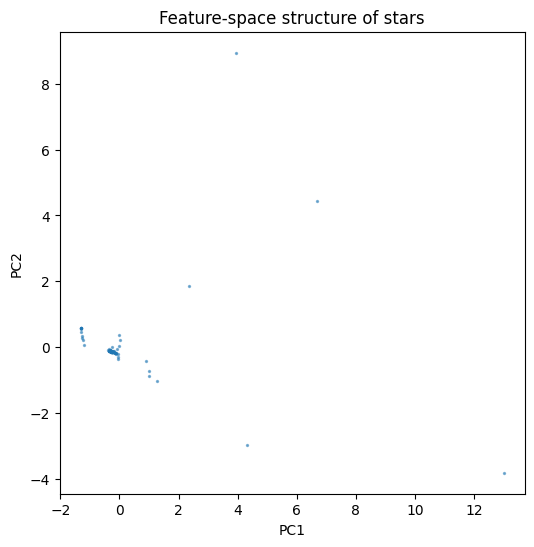

In [20]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

Xf = StandardScaler().fit_transform(df.values)
X_pca = PCA(n_components=2).fit_transform(Xf)

plt.figure(figsize=(6, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], s=2, alpha=0.5)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Feature-space structure of stars")
plt.show()
